# Single point calculation

Quantum dynamics requires a potential that computes the energy and forces.

PySCIVR supports the following potentials (see https://tsumura-m.github.io/PySCIVR/pyscivr.potentials.html for details):

- `ASEPotential`: a wrapper of [ASE](https://docs.ase-lib.org/) calculators for PySCIVR. Any quantum chemistry program supported by ASE, as well as neural network potentials such as MACE, can be used.

- `DFTPotential`: DFT energies and forces computed by [PySCF](https://pyscf.org/).

- `ZeroPotential`: returns zero for any geometry. Used for calculations that do not require the potential energy, such as pure rotation.

- `H2SplinePotential`: an analytical potential of H2 obtained by cubic spline interpolation of a CCSD(T)/aug-cc-pV5Z scan (0.4–1.5 Å, 0.02 Å spacing).

Examples for some of them are shown below.

## H2SplinePotential

No additional setup is required.

As in [ASE](https://docs.ase-lib.org/), PySCIVR uses Å for length and eV for energy
(see https://tsumura-m.github.io/PySCIVR/pyscivr.units.html for details).

Note that the input geometry is given in Å, and the output energy and forces are in eV and eV/Å, respectively.

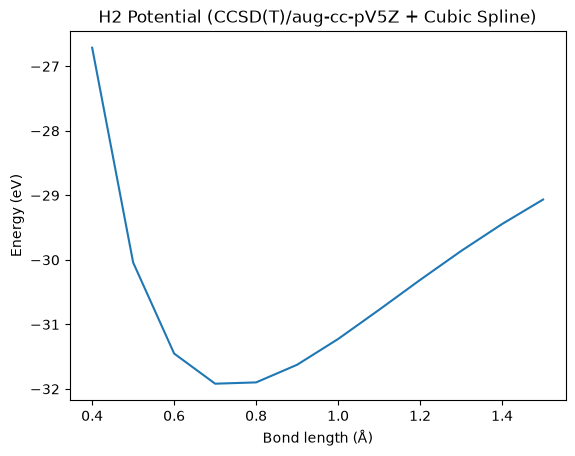

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pyscivr.potentials import H2SplinePotential

pot_h2 = H2SplinePotential()

ener_list = []
r_list = np.linspace(0.4, 1.5, 12)

for r in r_list:
    posi = np.array([[0.0, 0.0, 0.0], [0.0, 0.0, r]])
    ener, forces = pot_h2.energy_forces(posi)
    ener_list.append(ener)

plt.xlabel("Bond length (Å)")
plt.ylabel("Energy (eV)")
plt.title("H2 Potential (CCSD(T)/aug-cc-pV5Z + Cubic Spline)")
plt.plot(r_list, ener_list)
plt.show()

Batches of geometries are also supported.
`ASEPotential` and `DFTPotential` also accept batches, but the geometries are evaluated sequentially inside.

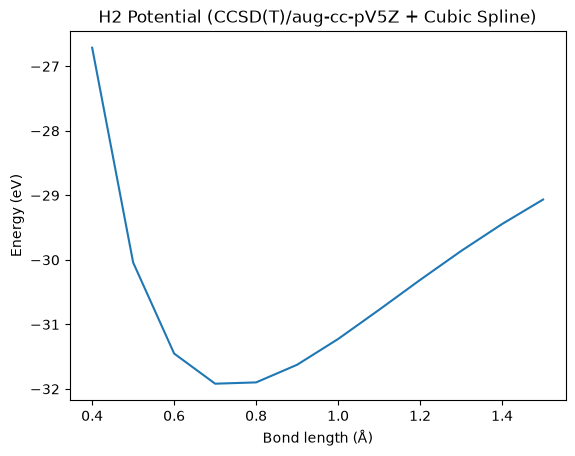

In [2]:
posi_list = np.array([[[0.0, 0.0, 0.0], [0.0, 0.0, r]] for r in r_list])
ener_list_batch_spline, _ = pot_h2.energy_forces(posi_list)

plt.xlabel("Bond length (Å)")
plt.ylabel("Energy (eV)")
plt.title("H2 Potential (CCSD(T)/aug-cc-pV5Z + Cubic Spline)")
plt.plot(r_list, ener_list_batch_spline)
plt.show()

## ASEPotential with MACE-ANI-CC

Here, the MACE-ANI-CC neural network potential is used.
ASE and the MACE-related packages are required, which can be installed by

```bash
uv sync --extra ase
```

The MACE model is loaded onto the CPU here.

Note that MACE-ANI-CC is trained for organic molecules and is not suitable for the dissociation of H2.
It is used here only to demonstrate the usage.

Reference:

D. P. Kovács, I. Batatia, E. S. Arany, and G. Csányi, "Evaluation of the MACE force field architecture: From medicinal chemistry to materials science," J. Chem. Phys. **159**, 044118 (2023).

cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.
Using ANI couple cluster model for MACECalculator, see https://doi.org/10.1063/5.0155322


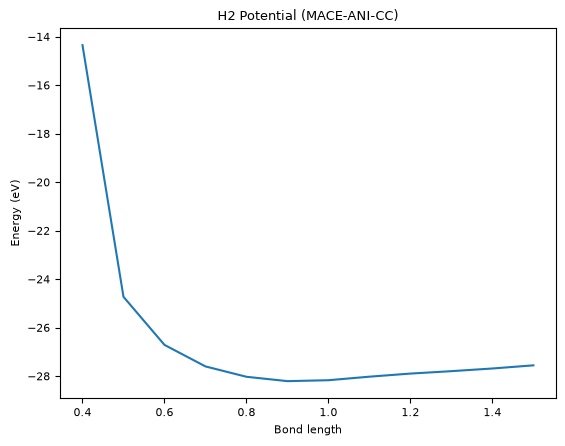

In [3]:
import numpy as np
import matplotlib.pyplot as plt

from pyscivr.potentials import mace_anicc_potential

import warnings
warnings.filterwarnings("ignore") # Ignore warnings from MACE

r_list = np.linspace(0.4, 1.5, 12)
posi_list = np.array([[[0.0, 0.0, 0.0], [0.0, 0.0, r]] for r in r_list])

pot_mace = mace_anicc_potential(['H', 'H'], device='cpu', num_threads=1)

ener_list_batch_mace, _ = pot_mace.energy_forces(posi_list)

plt.xlabel("Bond length")
plt.ylabel("Energy (eV)")
plt.title("H2 Potential (MACE-ANI-CC)")
plt.plot(r_list, ener_list_batch_mace)
plt.show()

## ASEPotential with ORCA

Here, ORCA is used through its ASE calculator. Calculators of other programs supported by ASE can be used in the same way.

In addition to

```bash
uv sync --extra ase
```

ORCA must be installed separately (free for academic use after registration at https://www.faccts.de/orca/).
Replace `path_to_orca` below with the full path to your ORCA executable.

Reference:

F. Neese, F. Wennmohs, U. Becker, and C. Riplinger, "The ORCA quantum chemistry program package," J. Chem. Phys. **152**, 224108 (2020).

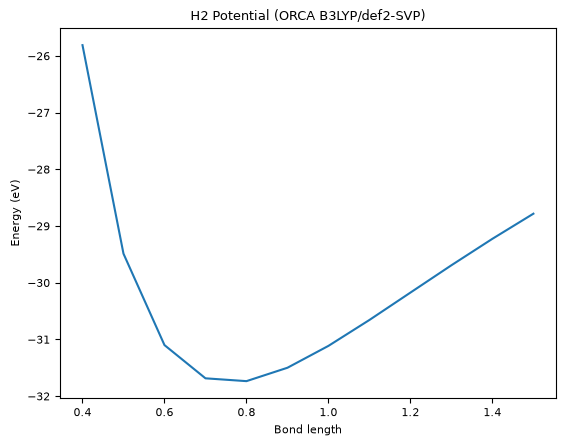

In [ ]:
from ase.calculators.orca import ORCA, OrcaProfile

import numpy as np
import matplotlib.pyplot as plt

from pyscivr.potentials import ASEPotential

import contextlib
import io

with contextlib.redirect_stdout(io.StringIO()): # Suppress output from ASE

    r_list = np.linspace(0.4, 1.5, 12)
    posi_list = np.array([[[0.0, 0.0, 0.0], [0.0, 0.0, r]] for r in r_list])

    path_to_orca = "/path/to/orca"  # Replace with the actual path to your ORCA executable
    profile = OrcaProfile(command=path_to_orca)
    calc = ORCA(profile=profile,
                charge=0, mult=1,
                orcasimpleinput="B3LYP def2-SVP TightSCF engrad",
                directory="orca_work")
    pot_orca = ASEPotential(symbols=['H', 'H'], calc=calc)

    ener_list_batch_orca, _ = pot_orca.energy_forces(posi_list)

    plt.xlabel("Bond length")
    plt.ylabel("Energy (eV)")
    plt.title("H2 Potential (ORCA B3LYP/def2-SVP)")
    plt.plot(r_list, ener_list_batch_orca)
    plt.show()

## DFTPotential

Here, DFT calculations with PySCF are used. PySCF can be installed by

```bash
uv sync --extra pyscf
```

Reference:

Q. Sun et al., "The Python simulations of chemistry framework: 10 years of an open-source quantum chemistry project," J. Chem. Phys. **165**, 102502 (2026).

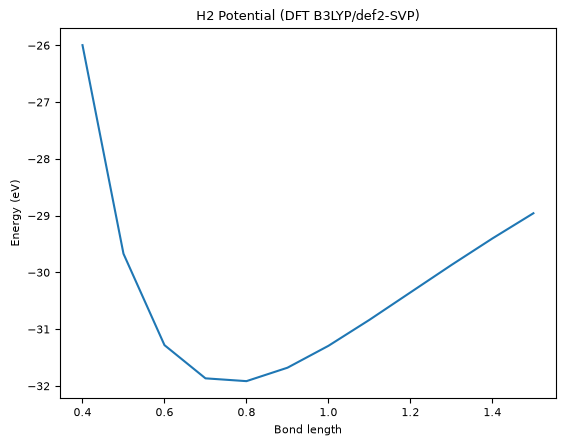

In [5]:
import numpy as np
import matplotlib.pyplot as plt

from pyscivr.potentials import DFTPotential

r_list = np.linspace(0.4, 1.5, 12)
posi_list = np.array([[[0.0, 0.0, 0.0], [0.0, 0.0, r]] for r in r_list])

pot_dft = DFTPotential(symbols=['H', 'H'], xc='B3LYP', basis='def2-SVP', charge=0, spin=0)

ener_list_batch_dft, _ = pot_dft.energy_forces(posi_list)

plt.xlabel("Bond length")
plt.ylabel("Energy (eV)")
plt.title("H2 Potential (DFT B3LYP/def2-SVP)")
plt.plot(r_list, ener_list_batch_dft)
plt.show()

## Compare the results from MACE, ORCA, and DFT calculations

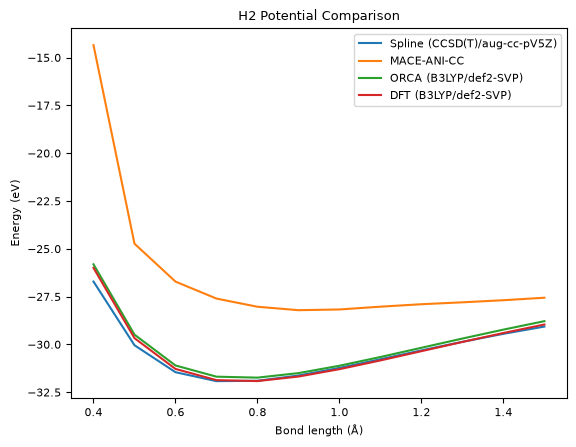

In [6]:
plt.plot(r_list, ener_list_batch_spline, label='Spline (CCSD(T)/aug-cc-pV5Z)')
plt.plot(r_list, ener_list_batch_mace, label='MACE-ANI-CC')
plt.plot(r_list, ener_list_batch_orca, label='ORCA (B3LYP/def2-SVP)')
plt.plot(r_list, ener_list_batch_dft, label='DFT (B3LYP/def2-SVP)')
plt.xlabel("Bond length (Å)")
plt.ylabel("Energy (eV)")
plt.title("H2 Potential Comparison")
plt.legend()
plt.show()